# 01 · Data analysis

Size, balance and vocabulary of every dataset. The last section measures *why* the plain-English challenge set is harder than the in-distribution test set.

In [1]:
import json, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from src.plotting import apply_style, hbar_groups, SERIES, MUTED, TEXT_SECONDARY
from src.preprocess import TextPreprocessor

apply_style()
pd.set_option("display.precision", 3)

def metrics(name):
    with open(os.path.join(ROOT, "results", "metrics", f"{name}.json"), encoding="utf-8") as f:
        return json.load(f)

def split(task, name):
    return TextPreprocessor.load_jsonl(os.path.join(ROOT, "data", "processed", task, f"{name}.jsonl"))

## Dataset sizes

In [2]:
cls = {s: split("classification", s) for s in ("train", "dev", "test", "challenge")}
ner = {s: split("ner", s) for s in ("train", "dev", "test")}
summ = {s: split("summarisation", s) for s in ("train", "test")}
qa = {}
for s in ("train", "test"):
    with open(os.path.join(ROOT, "data", "processed", "qa", f"{s}.json"), encoding="utf-8") as f:
        qa[s] = sum(len(p["qas"]) for d in json.load(f)["data"] for p in d["paragraphs"])
pd.DataFrame([
    {"task": "classification", **{k: len(v) for k, v in cls.items()}},
    {"task": "ner (sentences)", **{k: len(v) for k, v in ner.items()}},
    {"task": "qa (questions)", "train": qa["train"], "test": qa["test"]},
    {"task": "summarisation (pairs)", **{k: len(v) for k, v in summ.items()}},
]).set_index("task").fillna("-")

,train,dev,test,challenge
task,,,,
classification,102,24.0,42,30.0
ner (sentences),47,11.0,15,-
qa (questions),33,-,13,-
summarisation (pairs),27,-,12,-


## Classification: label balance per split

In [3]:
balance = pd.DataFrame({s: Counter(r["label"] for r in recs) for s, recs in cls.items()}).T
balance

,taxation,corporate_governance,workplace_relations
train,34,34,34
dev,8,8,8
test,14,14,14
challenge,10,10,10


## Sentence length by class (training split)

One panel per class, shared axes, so lengths compare directly.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


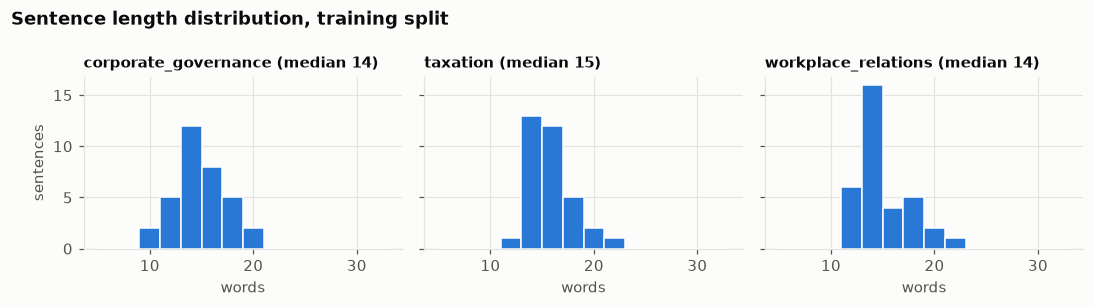

In [4]:
labels = sorted(balance.columns)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharex=True, sharey=True)
bins = np.arange(5, 35, 2)
for ax, label in zip(axes, labels):
    lengths = [len(r["text"].split()) for r in cls["train"] if r["label"] == label]
    ax.hist(lengths, bins=bins, color=SERIES[0], edgecolor="white", linewidth=1)
    ax.set_title(f"{label} (median {np.median(lengths):.0f})", fontsize=10)
    ax.set_xlabel("words")
axes[0].set_ylabel("sentences")
fig.suptitle("Sentence length distribution, training split", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()

## Why the challenge set is harder: vocabulary overlap with training

Share of each sentence's content words that never occur in the training split.

,mean OOV share,median
test,0.427,0.437
challenge,0.571,0.556


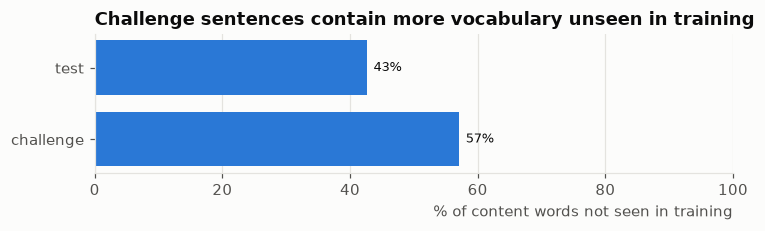

In [5]:
STOP = set("the a an of to and or in on for is are be by with as at that this it from must may can do i my we our".split())
def content(text):
    return [w.strip(".,?!'\"").lower() for w in text.split() if w.strip(".,?!'\"").lower() not in STOP]
train_vocab = {w for r in cls["train"] for w in content(r["text"])}
oov = {s: [np.mean([w not in train_vocab for w in content(r["text"])]) for r in cls[s]] for s in ("test", "challenge")}
table = pd.DataFrame({s: {"mean OOV share": np.mean(v), "median": np.median(v)} for s, v in oov.items()}).T
fig, ax = plt.subplots(figsize=(7, 2.2))
hbar_groups(ax, list(oov), {"mean share of unseen content words": [100 * np.mean(v) for v in oov.values()]},
            fmt="{:.0f}%", xlabel="% of content words not seen in training", xlim=(0, 100))
ax.set_title("Challenge sentences contain more vocabulary unseen in training")
fig.tight_layout()
table

## NER entity inventory

In [6]:
ents = Counter(t[2:] for s in ner["train"] + ner["dev"] + ner["test"] for t in s["labels"] if t.startswith("B-"))
pd.DataFrame.from_dict(ents, orient="index", columns=["entities"]).sort_values("entities", ascending=False)

,entities
GOV_BODY,35
FINANCIAL_TERM,34
REGULATORY_ACT,21
ORG,16
